# RQ3 Robustness on manually reviewed real documents




## 1. Setup




In [178]:
from pathlib import Path
import json, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 140)

plt.rcParams.update({
    "figure.dpi": 170,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

sid = "b10a2abb3ea1"
name_labs = {"FULL_NAME", "FIRST_NAME", "LAST_NAME", "Name"}
direct = {"FULL_NAME", "FIRST_NAME", "LAST_NAME", "Student number", "Institutional email"}
show = {
    "FULL_NAME": "Full name",
    "FIRST_NAME": "First name",
    "LAST_NAME": "Last name",
    "Student number": "Student no.",
    "Institutional email": "Inst. email",
    "Course code": "Course code",
    "Group label": "Group label",
    "Programme": "Programme",
    "Date": "Date",
    "Role": "Role",
    "Other": "Other",
}

def repo():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "document_generator").exists() and (q / "thesis_project").exists():
            return q
        if (q / "UI").exists() and (q / "notebooks").exists():
            return q
    return p

def norm(x):
    s = unicodedata.normalize("NFKD", str(x or ""))
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", s.strip().lower())

def key(x):
    return re.sub(r"[^a-z0-9]+", "", norm(x))

def vals(x):
    return [v.strip() for v in str(x or "").split("|") if v.strip() and v.strip().lower() not in {"nan", "ng"}]

def join(xs):
    seen, out = set(), []
    for x in xs:
        s, k = str(x or "").strip(), norm(x)
        if s and k not in seen:
            seen.add(k)
            out.append(s)
    return "|".join(out)

def rate(a, b):
    return float(a) / float(b) if b else 0.0

root = repo()
img = root / "images"
img.mkdir(parents=True, exist_ok=True)



## 2. Load the reviewed UI states

The notebook uses the saved UI state files directly. This keeps the reviewed annotations separate from the original documents and avoids depending on regenerated CSV files.




In [179]:
bases = [
    root / "UI" / "rq3_labeling_workspace" / sid,
    root / "UI" / "rq3_labeling_workspace_BACKUP" / sid,
]

folders = []
for b in bases:
    folders += [b / "states", b / "export_build" / "saved_review_state" / "doc_states"]

active = []
for b in bases:
    f = b / "session.json"
    if f.exists() and not active:
        active = [d["doc_id"] for d in json.loads(f.read_text(encoding="utf-8")).get("documents", [])]

seen = {}
for order, folder in enumerate(folders):
    if not folder.exists():
        continue
    for p in sorted(folder.glob("*.json")):
        s = json.loads(p.read_text(encoding="utf-8"))
        did = str(s.get("doc_id", p.stem))
        if did not in seen:
            seen[did] = (order, s)

states = [seen[d][1] for d in active if d in seen] if active else [v[1] for v in seen.values()]
assert states, "No RQ3 state files found. Check sid and the UI workspace folder."



## 3. Build the reviewed reference set

The audit keeps `Name`, `FULL_NAME`, `FIRST_NAME`, and `LAST_NAME` visible. For thesis results, `Name` is mapped to `FULL_NAME`, but full names, first names, and last names stay separate. A first-name or last-name mention is counted as missed only when the automatic pipeline did not detect that name part and did not detect a covering `Name` or `FULL_NAME` mention. A full-name mention is counted as covered when the automatic pipeline detected the full name or detected both matching name parts.




In [180]:
rows = []
for s in states:
    for e in s.get("entities", []):
        st = str(e.get("status", "accepted"))
        if st not in {"accepted", "manual"}:
            continue

        src = str(e.get("source", ""))
        raw = str(e.get("label", "Other") or "Other")
        det = "FULL_NAME" if raw == "Name" else raw
        lab = det
        was_manual = bool(e.get("manual")) or st == "manual" or src in {"manual", "manual_review"}

        rows.append({
            "doc_id": s.get("doc_id", ""),
            "file": s.get("file_name", ""),
            "rel": s.get("relative_path", ""),
            "ext": s.get("extension", ""),
            "raw": raw,
            "detail": det,
            "label": lab,
            "kind": "direct" if lab in direct else "quasi",
            "surface": str(e.get("surface", "")),
            "region": e.get("region", ""),
            "path": e.get("path", ""),
            "start": int(e.get("start", -1) or -1),
            "end": int(e.get("end", -1) or -1),
            "source": src,
            "manual_raw": was_manual,
            "auto_raw": not was_manual,
            "id": str(e.get("id", "")),
        })

ann = pd.DataFrame(rows)
ann["txt"] = ann["surface"].map(norm)
ann["k"] = ann["surface"].map(key)
ann["contained_name_part"] = False

span = ann["start"].ge(0) & ann["end"].gt(ann["start"])

for _, g in ann[ann["detail"].isin(name_labs)].groupby(["doc_id", "path"]):
    full = g[g["detail"].eq("FULL_NAME") & span.loc[g.index]]
    part = g[g["detail"].isin(["FIRST_NAME", "LAST_NAME"])]
    for i, r in part.iterrows():
        by_span = any(r["start"] >= f["start"] and r["end"] <= f["end"] for _, f in full.iterrows())
        by_text = any(r["k"] and r["k"] in f["k"] and len(f["k"]) > len(r["k"]) for _, f in full.iterrows())
        ann.loc[i, "contained_name_part"] = bool(by_span or by_text)

ann = ann.drop_duplicates(subset=["doc_id", "path", "start", "end", "detail", "k", "source"]).reset_index(drop=True)

def toks(x):
    return [key(t) for t in re.findall(r"[A-Za-zÀ-ÖØ-öø-ÿ0-9'’-]+", str(x or "")) if key(t)]

def has_span(r):
    return int(r["start"]) >= 0 and int(r["end"]) > int(r["start"])

def covers(a, b):
    return str(a["path"]) == str(b["path"]) and has_span(a) and has_span(b) and int(a["start"]) <= int(b["start"]) and int(a["end"]) >= int(b["end"])

def same_part(part, detail, autos):
    return len(autos[(autos["detail"].eq(detail)) & (autos["k"].eq(part))]) > 0

def full_covers_part(r, autos):
    for _, a in autos[autos["detail"].eq("FULL_NAME")].iterrows():
        if covers(a, r):
            return True
        if r["k"] and r["k"] in toks(a["surface"]):
            return True
        if r["k"] and r["k"] in a["k"] and len(a["k"]) > len(r["k"]):
            return True
    return False

def full_seen(r, autos):
    rt = toks(r["surface"])
    for _, a in autos[autos["detail"].eq("FULL_NAME")].iterrows():
        if r["k"] and (r["k"] == a["k"] or r["k"] in a["k"] or a["k"] in r["k"]):
            return True
        if covers(a, r) or covers(r, a):
            return True

    if len(rt) >= 2:
        return same_part(rt[0], "FIRST_NAME", autos) and same_part(rt[-1], "LAST_NAME", autos)
    if len(rt) == 1:
        return same_part(rt[0], "FIRST_NAME", autos) or same_part(rt[0], "LAST_NAME", autos)
    return False

def name_auto(r):
    if r["detail"] not in name_labs:
        return bool(r["auto_raw"])

    autos = ann[ann["doc_id"].eq(r["doc_id"]) & ann["auto_raw"] & ann["detail"].isin(name_labs)]

    if r["detail"] in {"FIRST_NAME", "LAST_NAME"}:
        return same_part(r["k"], r["detail"], autos) or full_covers_part(r, autos)

    return full_seen(r, autos)

gold = ann.copy()
gold["auto"] = gold.apply(name_auto, axis=1)
gold["manual"] = ~gold["auto"]
gold["show"] = gold["label"].map(show).fillna(gold["label"])
gold["label_display"] = gold["show"]
gold["kind"] = np.where(gold["label"].isin(direct), "direct", "quasi")

gold = gold.drop_duplicates(subset=["doc_id", "path", "start", "end", "label", "k"]).reset_index(drop=True)

name_policy = pd.DataFrame([{
    "raw_name_mentions": int(ann["detail"].isin(name_labs).sum()),
    "contained_first_last_in_audit": int(ann["contained_name_part"].sum()),
    "clean_mentions": len(gold),
    "full_name_mentions": int(gold["label"].eq("FULL_NAME").sum()),
    "first_name_mentions": int(gold["label"].eq("FIRST_NAME").sum()),
    "last_name_mentions": int(gold["label"].eq("LAST_NAME").sum()),
    "full_name_manual_misses": int(gold[gold["label"].eq("FULL_NAME")]["manual"].sum()),
    "first_name_manual_misses": int(gold[gold["label"].eq("FIRST_NAME")]["manual"].sum()),
    "last_name_manual_misses": int(gold[gold["label"].eq("LAST_NAME")]["manual"].sum()),
}])

raw_labels = ann.groupby(["raw", "kind"], as_index=False).agg(
    mentions=("surface", "count"),
    automatic_raw=("auto_raw", "sum"),
    manual_raw=("manual_raw", "sum"),
).sort_values("mentions", ascending=False)

display(raw_labels)
display(name_policy)



,raw,kind,mentions,automatic_raw,manual_raw
2,FIRST_NAME,direct,2018,1225,793
3,FULL_NAME,direct,1161,1085,76
6,LAST_NAME,direct,779,773,6
7,Name,direct,718,718,0
1,Date,quasi,247,178,69
4,Group label,quasi,69,56,13
0,Course code,quasi,49,6,43
5,Institutional email,direct,7,7,0
10,Role,quasi,7,7,0
8,Other,quasi,1,0,1


,raw_name_mentions,contained_first_last_in_audit,clean_mentions,full_name_mentions,first_name_mentions,last_name_mentions,full_name_manual_misses,first_name_manual_misses,last_name_manual_misses
0,4676,1112,4339,1161,2018,779,73,685,6


## 4. RQ3 scope, label recall and document-type recall

RQ3 uses manual-review recall. This is the share of the final reviewed reference labels that were already detected automatically before manual correction.




In [181]:
def dtype(x):
    s = norm(x)
    if "agenda" in s:
        return "agenda"
    if "minute" in s:
        return "minutes"
    if "poster" in s:
        return "poster"
    if "presentation" in s or "slide" in s:
        return "presentation"
    if "planning" in s or "chart" in s or "phase" in s:
        return "Gantt chart"
    if "overview" in s:
        return "overview"
    if "assignment" in s or "charter" in s:
        return "assignment"
    if "test" in s or "result" in s:
        return "personality test"
    return "pdf-other" if str(x).lower().endswith(".pdf") else "other"

doc = pd.DataFrame([{
    "doc_id": s.get("doc_id", ""),
    "file": s.get("file_name", ""),
    "rel": s.get("relative_path", ""),
    "ext": s.get("extension", ""),
    "size": int(s.get("file_size_bytes", 0) or 0),
} for s in states])
doc["type"] = doc["rel"].map(dtype)

cnt = gold.groupby("doc_id").agg(
    mentions=("surface", "count"),
    auto=("auto", "sum"),
    manual=("manual", "sum"),
    direct=("kind", lambda x: int((x == "direct").sum())),
    quasi=("kind", lambda x: int((x == "quasi").sum())),
).reset_index()

doc = doc.merge(cnt, on="doc_id", how="left").fillna(0)
for c in ["mentions", "auto", "manual", "direct", "quasi"]:
    doc[c] = doc[c].astype(int)

doc["visual"] = doc["type"].str.contains("poster|presentation|chart|overview", regex=True)
doc["low"] = doc["mentions"].le(3)
doc["recall"] = doc.apply(lambda r: rate(r["auto"], r["mentions"]), axis=1)
doc["manual_share"] = doc.apply(lambda r: rate(r["manual"], r["mentions"]), axis=1)

def agg(g):
    return pd.Series({
        "documents": g["doc_id"].nunique(),
        "reviewed": g["mentions"].sum(),
        "direct": g["direct"].sum(),
        "quasi": g["quasi"].sum(),
        "auto": g["auto"].sum(),
        "manual": g["manual"].sum(),
        "recall": rate(g["auto"].sum(), g["mentions"].sum()),
        "manual_share": rate(g["manual"].sum(), g["mentions"].sum()),
        "median_mentions": g["mentions"].median(),
    })

scope = pd.DataFrame([{
    "documents": doc["doc_id"].nunique(),
    "document_types": doc["type"].nunique(),
    "file_formats": doc["ext"].nunique(),
    "reviewed_mentions": len(gold),
    "direct_mentions": int((gold["kind"] == "direct").sum()),
    "quasi_mentions": int((gold["kind"] == "quasi").sum()),
    "manual_review_recall": rate(gold["auto"].sum(), len(gold)),
    "manual_share": rate(gold["manual"].sum(), len(gold)),
    "low_or_no_pii_documents": int(doc["low"].sum()),
    "visual_documents": int(doc["visual"].sum()),
}])

labels = gold.groupby(["label", "show", "kind"], as_index=False).agg(
    reviewed=("surface", "count"),
    auto=("auto", "sum"),
    manual=("manual", "sum"),
)
labels["recall"] = labels.apply(lambda r: rate(r["auto"], r["reviewed"]), axis=1)
labels["manual_share"] = labels.apply(lambda r: rate(r["manual"], r["reviewed"]), axis=1)
labels = labels.sort_values("reviewed", ascending=False)

types = doc.groupby("type").apply(agg).reset_index().sort_values(["documents", "reviewed"], ascending=False)
formats = doc.groupby("ext").apply(agg).reset_index().sort_values("documents", ascending=False)

label_table = labels[["show", "kind", "reviewed", "auto", "manual", "recall", "manual_share"]]
type_table = types[["type", "documents", "reviewed", "auto", "manual", "recall", "manual_share", "median_mentions"]]
format_table = formats[["ext", "documents", "reviewed", "recall", "manual_share", "median_mentions"]]

display(Markdown("### Scope")); display(scope.round(3))
display(Markdown("### Reviewed labels")); display(label_table.round(3))
display(Markdown("### Document types")); display(type_table.round(3))
display(Markdown("### File formats")); display(format_table.round(3))



### Scope

,documents,document_types,file_formats,reviewed_mentions,direct_mentions,quasi_mentions,manual_review_recall,manual_share,low_or_no_pii_documents,visual_documents
0,83,9,2,4339,3965,374,0.795,0.205,8,21


### Reviewed labels

,show,kind,reviewed,auto,manual,recall,manual_share
2,First name,direct,2018,1333,685,0.661,0.339
3,Full name,direct,1161,1088,73,0.937,0.063
6,Last name,direct,779,773,6,0.992,0.008
1,Date,quasi,247,178,69,0.721,0.279
4,Group label,quasi,69,56,13,0.812,0.188
0,Course code,quasi,49,6,43,0.122,0.878
5,Inst. email,direct,7,7,0,1.000,0.000
9,Role,quasi,7,7,0,1.000,0.000
7,Other,quasi,1,0,1,0.000,1.000
8,Programme,quasi,1,0,1,0.000,1.000


### Document types

,type,documents,reviewed,auto,manual,recall,manual_share,median_mentions
1,agenda,31.0,1737.0,1643.0,94.0,0.946,0.054,57.0
3,minutes,21.0,1353.0,1285.0,68.0,0.950,0.050,67.0
0,Gantt chart,17.0,922.0,418.0,504.0,0.453,0.547,54.0
6,personality test,6.0,20.0,20.0,0.0,1.000,0.000,2.5
5,pdf-other,3.0,59.0,42.0,17.0,0.712,0.288,20.0
4,overview,2.0,221.0,17.0,204.0,0.077,0.923,110.5
7,poster,1.0,25.0,23.0,2.0,0.920,0.080,25.0
8,presentation,1.0,2.0,0.0,2.0,0.000,1.000,2.0
2,assignment,1.0,0.0,0.0,0.0,0.000,0.000,0.0


### File formats

,ext,documents,reviewed,recall,manual_share,median_mentions
1,.pdf,74.0,4070.0,0.788,0.212,58.5
0,.docx,9.0,269.0,0.900,0.100,35.0


## 5. Thesis figures




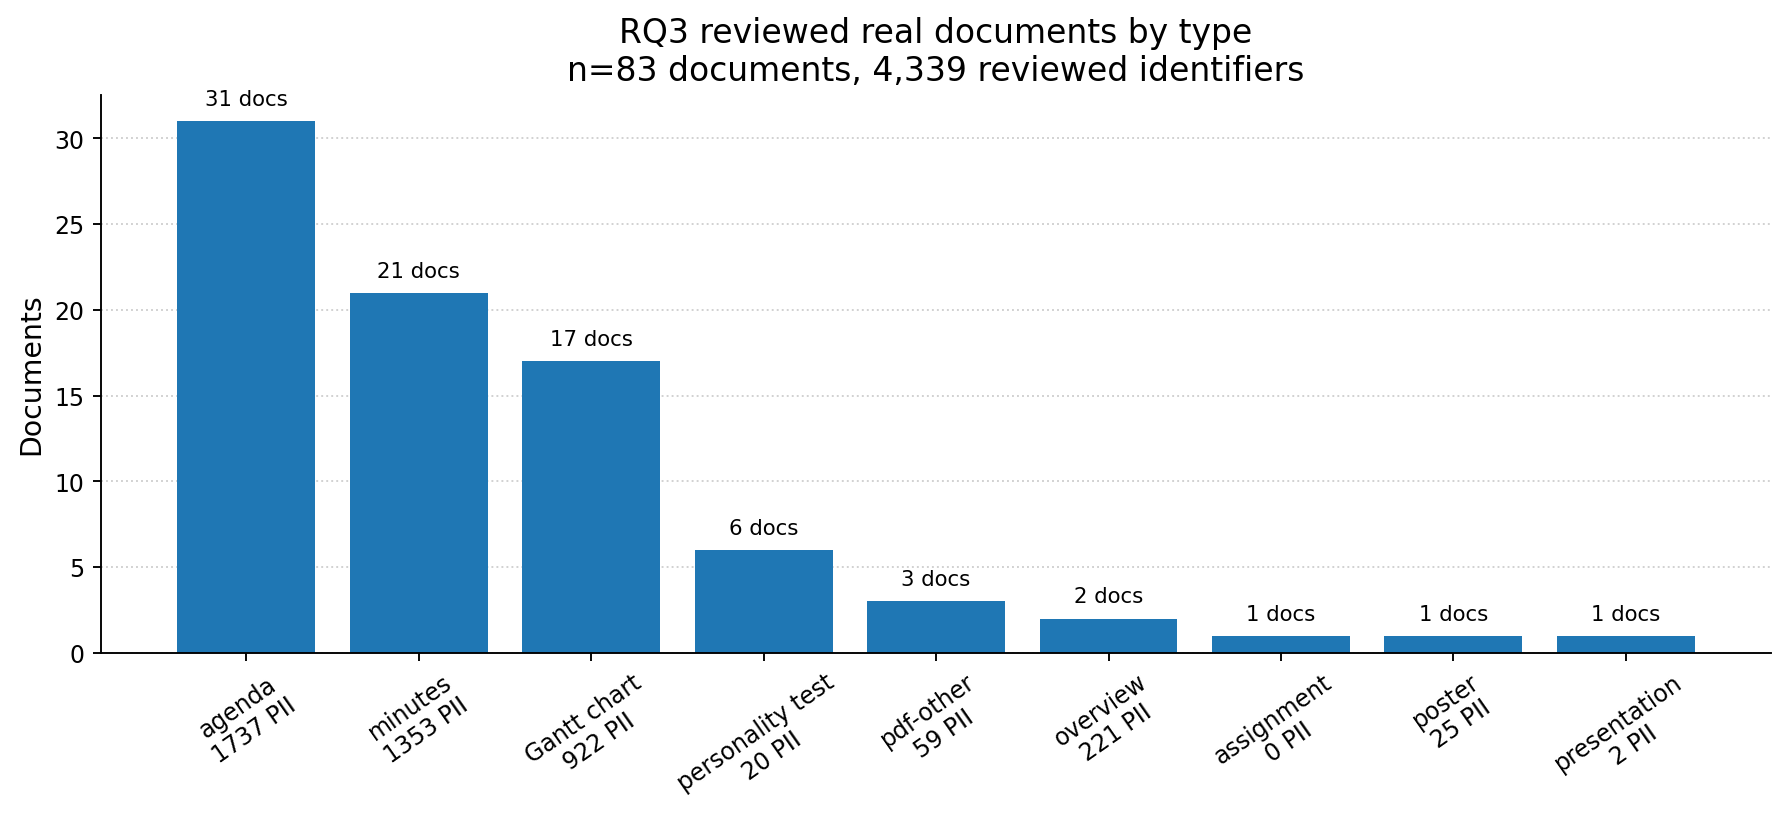

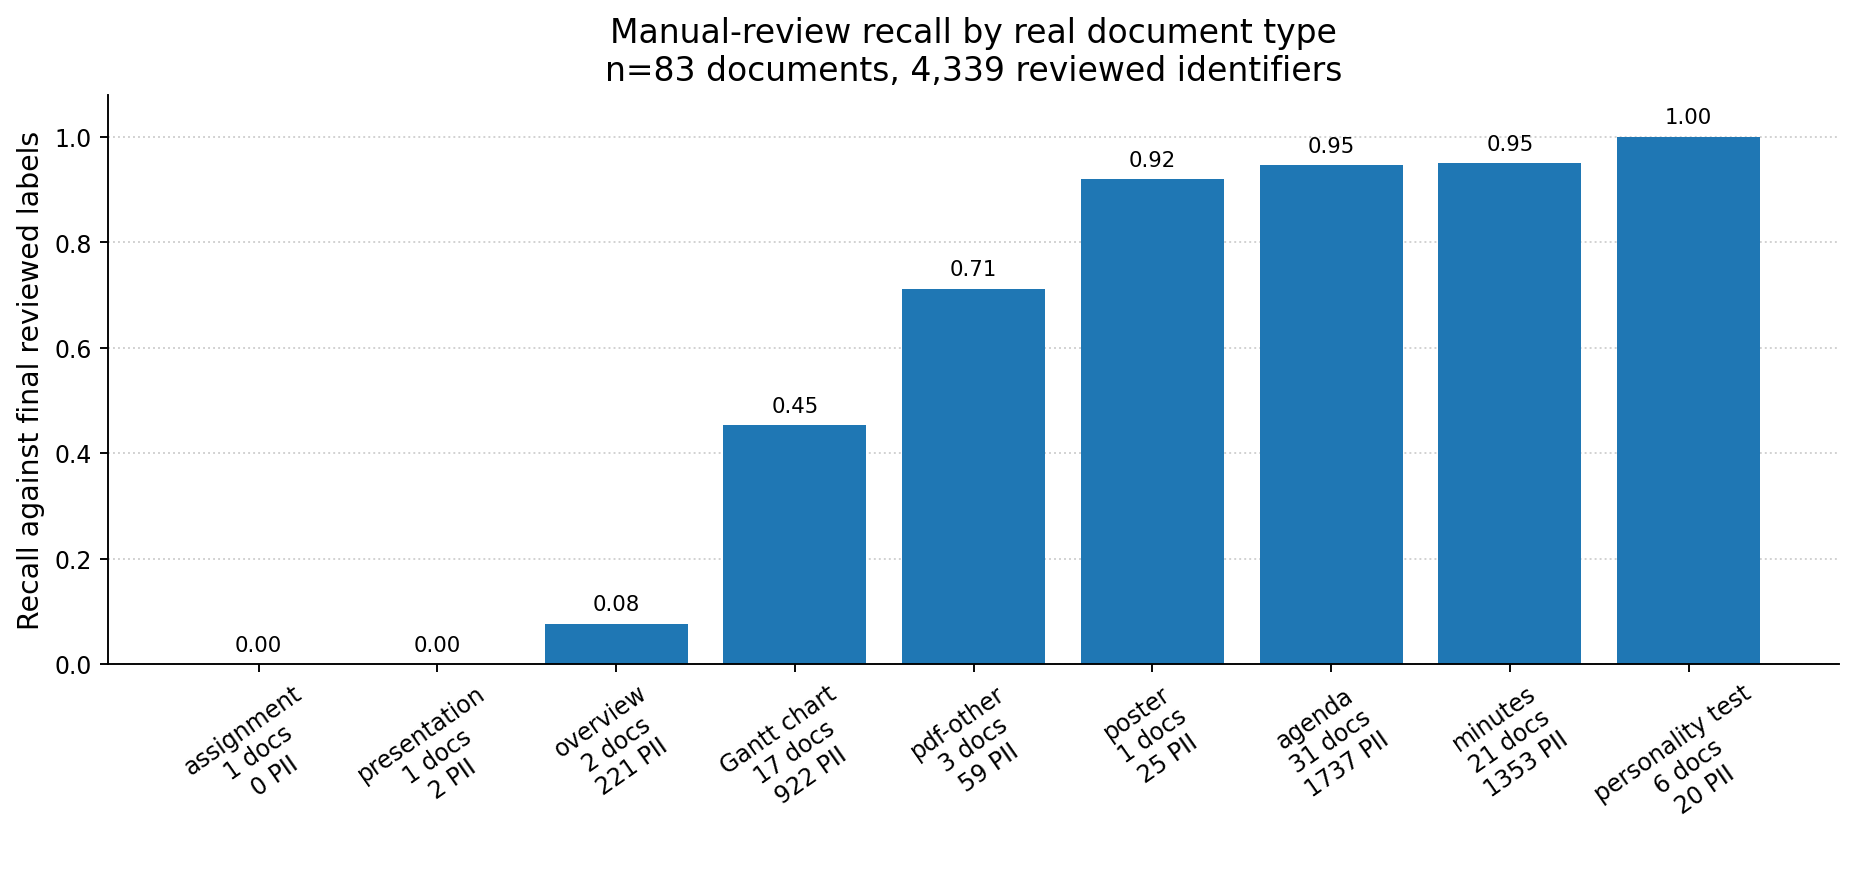

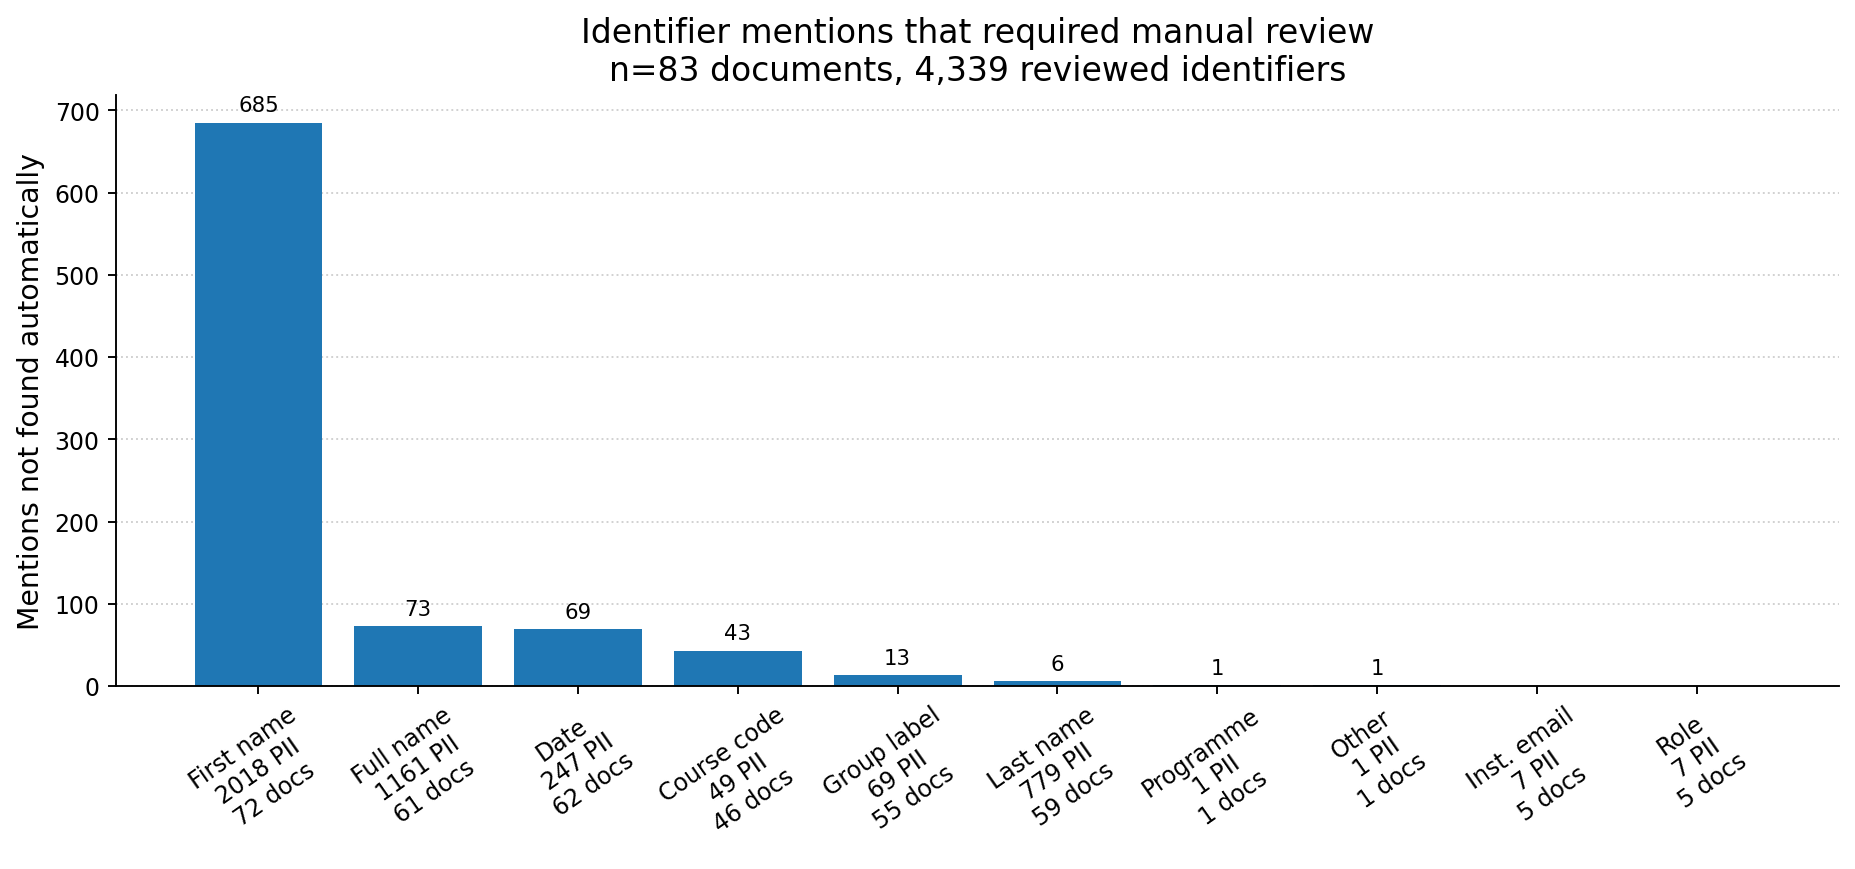

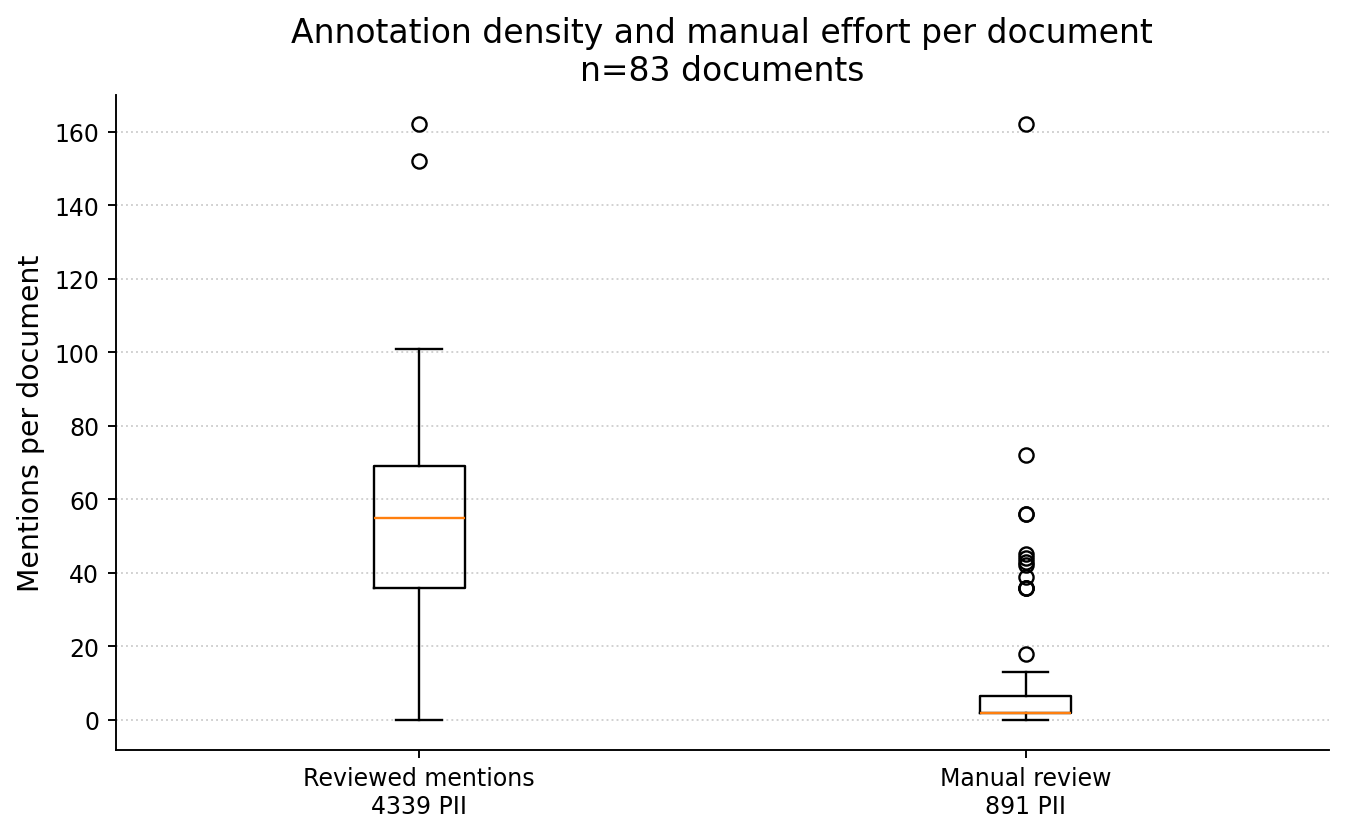

In [182]:
def savefig(name):
    plt.savefig(img / f"{name}.png", bbox_inches="tight")
    plt.show()


def rate(a, b):
    return float(a) / float(b) if b else 0.0


d = doc.copy()
g = gold.copy()

if "label_display" not in g.columns:
    g["label_display"] = g["label"]

if "manual" in g.columns:
    g["_manual"] = g["manual"].astype(str).str.lower().isin(["true", "1", "yes", "manual"])
elif "status" in g.columns:
    g["_manual"] = g["status"].astype(str).str.lower().eq("manual")
elif "source" in g.columns:
    g["_manual"] = g["source"].astype(str).str.lower().str.contains("manual")
else:
    g["_manual"] = False

g["_auto"] = ~g["_manual"]

for col in ["mentions", "auto", "manual", "direct", "quasi"]:
    if col not in d.columns:
        d[col] = 0

type_df = (
    d.groupby("type", as_index=False)
    .agg(
        documents=("doc_id", "nunique"),
        reviewed=("mentions", "sum"),
        auto=("auto", "sum"),
        manual=("manual", "sum"),
        direct=("direct", "sum"),
        quasi=("quasi", "sum"),
        median_mentions=("mentions", "median"),
    )
)

type_df["recall"] = type_df.apply(lambda r: rate(r["auto"], r["reviewed"]), axis=1)
type_df["manual_share"] = type_df.apply(lambda r: rate(r["manual"], r["reviewed"]), axis=1)

label_df = (
    g.groupby("label_display", as_index=False)
    .agg(
        reviewed=("doc_id", "size"),
        documents=("doc_id", "nunique"),
        auto=("_auto", "sum"),
        manual=("_manual", "sum"),
    )
)

label_df["recall"] = label_df.apply(lambda r: rate(r["auto"], r["reviewed"]), axis=1)
label_df["manual_share"] = label_df.apply(lambda r: rate(r["manual"], r["reviewed"]), axis=1)

n_docs = int(d["doc_id"].nunique())
n_ids = int(g.shape[0])


fig, ax = plt.subplots(figsize=(10.4, 4.8), constrained_layout=True)

x = type_df.sort_values("documents", ascending=False)

labels = [
    f"{r.type}\n{int(r.reviewed)} PII"
    for r in x.itertuples(index=False)
]

ax.bar(labels, x["documents"])
ax.set_title(f"RQ3 reviewed real documents by type\nn={n_docs} documents, {n_ids:,} reviewed identifiers")
ax.set_ylabel("Documents")
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.set_axisbelow(True)

top = max(int(x["documents"].max()), 1)
for i, r in enumerate(x.itertuples(index=False)):
    ax.text(i, r.documents + top * 0.03, f"{int(r.documents)} docs", ha="center", fontsize=9)

ax.tick_params(axis="x", rotation=35)
savefig("rq3_documents_by_type")


fig, ax = plt.subplots(figsize=(10.8, 5.0), constrained_layout=True)

x = type_df.sort_values("recall")

labels = [
    f"{r.type}\n{int(r.documents)} docs\n{int(r.reviewed)} PII"
    for r in x.itertuples(index=False)
]

ax.bar(labels, x["recall"])
ax.set_title(f"Manual-review recall by real document type\nn={n_docs} documents, {n_ids:,} reviewed identifiers")
ax.set_ylabel("Recall against final reviewed labels")
ax.set_ylim(0, 1.08)
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.set_axisbelow(True)

for i, r in enumerate(x.itertuples(index=False)):
    ax.text(i, r.recall + 0.025, f"{r.recall:.2f}", ha="center", fontsize=9)

ax.tick_params(axis="x", rotation=35)
savefig("rq3_recall_by_document_type")


fig, ax = plt.subplots(figsize=(10.8, 5.0), constrained_layout=True)

x = label_df.sort_values("manual", ascending=False)

labels = [
    f"{r.label_display}\n{int(r.reviewed)} PII\n{int(r.documents)} docs"
    for r in x.itertuples(index=False)
]

ax.bar(labels, x["manual"])
ax.set_title(f"Identifier mentions that required manual review\nn={n_docs} documents, {n_ids:,} reviewed identifiers")
ax.set_ylabel("Mentions not found automatically")
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.set_axisbelow(True)

top = max(int(x["manual"].max()), 1)
for i, r in enumerate(x.itertuples(index=False)):
    if r.manual > 0:
        ax.text(i, r.manual + top * 0.02, f"{int(r.manual)}", ha="center", fontsize=9)

ax.tick_params(axis="x", rotation=35)
savefig("rq3_manual_additions_by_label")


fig, ax = plt.subplots(figsize=(7.8, 4.8), constrained_layout=True)

ax.boxplot(
    [d["mentions"], d["manual"]],
    tick_labels=[
        f"Reviewed mentions\n{int(d['mentions'].sum())} PII",
        f"Manual review\n{int(d['manual'].sum())} PII",
    ],
)

ax.set_title(f"Annotation density and manual effort per document\nn={n_docs} documents")
ax.set_ylabel("Mentions per document")
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.set_axisbelow(True)



## 6. Real and synthetic document comparison

This is useful for the discussion because it shows that RQ3 is not just another synthetic test. The real review set contains many PDFs, low/no-PII documents and visual documents.




,separator,real,synthetic
0,PDF share,0.892,0.000
1,Low/no-PII share,0.096,0.000
2,Median identifier mentions,55.000,73.000
3,Median quasi-identifier share,0.060,0.132


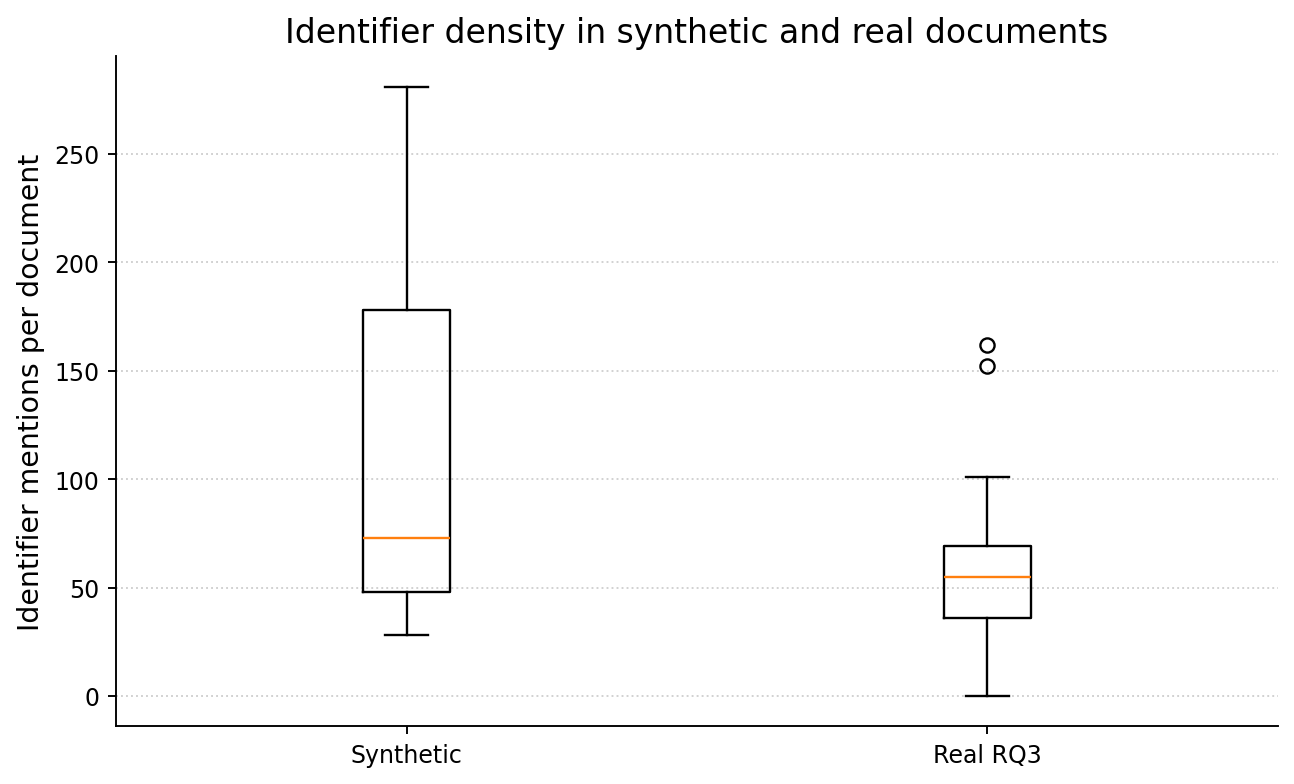

In [183]:
def synth_docs():
    ds = root / "notebooks" / "workspace" / "dataset"
    docs = ds / "documents"
    anns = ds / "annotations"
    if not docs.exists() or not anns.exists():
        return pd.DataFrame()
    paths = {p.stem: p for p in docs.glob("*") if p.is_file()}
    out = []
    for p in anns.glob("*.json"):
        js = json.loads(p.read_text(encoding="utf-8"))
        q = paths.get(p.stem)
        labs = []
        for e in js.get("entities", []) or []:
            n = max(1, len(e.get("occurrences", []) or []))
            labs += ["FULL_NAME" if e.get("label") == "Name" else e.get("label", "")] * n
        for im in js.get("images", []) or []:
            for e in im.get("entities", []) or []:
                labs.append("FULL_NAME" if e.get("label") == "Name" else e.get("label", ""))
        t = norm(js.get("template_id", p.stem))
        out.append({
            "source": "Synthetic",
            "ext": q.suffix.lower() if q else "",
            "type": "agenda" if "agenda" in t else "minutes" if "minute" in t else "planning/chart",
            "mentions": len(labs),
            "quasi_share": rate(sum(x not in direct for x in labs), len(labs)),
            "low": len(labs) <= 3,
        })
    return pd.DataFrame(out)

syn = synth_docs()
real = doc.copy()
real["source"] = "Real RQ3"
real["quasi_share"] = real.apply(lambda r: rate(r["quasi"], r["mentions"]), axis=1)
real = real[["source", "ext", "type", "mentions", "quasi_share", "low"]]

if len(syn):
    sep = pd.DataFrame([
        {"separator": "PDF share", "real": rate((real["ext"] == ".pdf").sum(), len(real)), "synthetic": rate((syn["ext"] == ".pdf").sum(), len(syn))},
        {"separator": "Low/no-PII share", "real": real["low"].mean(), "synthetic": syn["low"].mean()},
        {"separator": "Median identifier mentions", "real": real["mentions"].median(), "synthetic": syn["mentions"].median()},
        {"separator": "Median quasi-identifier share", "real": real["quasi_share"].median(), "synthetic": syn["quasi_share"].median()},
    ])
    display(sep.round(3))
    fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
    ax.boxplot([syn["mentions"], real["mentions"]], tick_labels=["Synthetic", "Real RQ3"])
    ax.set_title("Identifier density in synthetic and real documents")
    ax.set_ylabel("Identifier mentions per document")
    ax.grid(axis="y", linestyle=":", alpha=0.6)
    savefig("rq3_real_vs_synthetic_density")
else:
    sep = pd.DataFrame()

